<a href="https://colab.research.google.com/github/estmichellartund-beep/IPYNB/blob/main/Data_Set_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("¡Hola! Google Colab está ejecutando Python correctamente.")

¡Hola! Google Colab está ejecutando Python correctamente.


1. LIBRERIAS

In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 1: IMPORTACIÓN DE LIBRERÍAS
# ============================================

import os
import zipfile

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display

# Configuración de visualización
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 30)
pd.set_option("display.width", 150)

# Confirmar importación
print("======================================")
print("LIBRERÍAS IMPORTADAS CORRECTAMENTE")
print("======================================")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

print("\nEntorno de trabajo preparado correctamente.")

LIBRERÍAS IMPORTADAS CORRECTAMENTE
Pandas: 2.2.3
NumPy: 2.4.6
Matplotlib: 3.10.0

Entorno de trabajo preparado correctamente.


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 2: CARGAR ARCHIVO EXCEL
# ============================================

from google.colab import files
import os

print("Selecciona el archivo Excel del Dataset SNIES.")

# Abrir ventana para seleccionar el archivo
archivos_subidos = files.upload()

# Identificar archivos Excel
archivos_excel = [
    nombre for nombre in archivos_subidos.keys()
    if nombre.lower().endswith((".xlsx", ".xls"))
]

# Verificar que se haya seleccionado un Excel
if not archivos_excel:
    raise ValueError(
        "No se encontró un archivo Excel. "
        "Por favor, selecciona el archivo del Dataset SNIES."
    )

# Seleccionar el archivo esperado, si está disponible
nombre_esperado = "Dataset_SNIES_2016_2025_actualizado_auditado.xlsx"

if nombre_esperado in archivos_excel:
    nombre_excel = nombre_esperado
else:
    nombre_excel = archivos_excel[0]

# Guardar la ruta del archivo
ruta_excel = os.path.join("/content", nombre_excel)

print("\n======================================")
print("ARCHIVO CARGADO CORRECTAMENTE")
print("======================================")
print("Nombre:", nombre_excel)
print("Ruta:", ruta_excel)
print("Tamaño:", round(os.path.getsize(ruta_excel) / 1024, 2), "KB")

Selecciona el archivo Excel del Dataset SNIES.


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 3: LEER LAS HOJAS DEL ARCHIVO EXCEL
# ============================================

# Leer todas las hojas del libro
hojas = pd.read_excel(
    ruta_excel,
    sheet_name=None,
    engine="openpyxl"
)

# Mostrar las hojas disponibles
print("======================================")
print("HOJAS DEL ARCHIVO EXCEL")
print("======================================")

for nombre_hoja, tabla in hojas.items():
    print(
        f"{nombre_hoja}: "
        f"{tabla.shape[0]} filas y "
        f"{tabla.shape[1]} columnas"
    )

# Identificar la hoja principal
nombre_principal = next(
    (
        nombre for nombre in hojas
        if nombre.strip().casefold() == "dataset_1"
    ),
    None
)

# Comprobar que existe la hoja principal
if nombre_principal is None:
    raise ValueError(
        "No se encontró la hoja Dataset_1. "
        "Revisa los nombres de las hojas mostradas anteriormente."
    )

# Cargar el Dataset principal
df = hojas[nombre_principal].copy()

print("\n======================================")
print("DATASET PRINCIPAL CARGADO")
print("======================================")

print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

print("\nNombres de las columnas:")
print(df.columns.tolist())

print("\nPrimeros cinco registros:")
display(df.head())

HOJAS DEL ARCHIVO EXCEL
Dataset_1: 330 filas y 10 columnas
Totales_Departamento: 330 filas y 6 columnas
Nacional_Niveles: 10 filas y 7 columnas
Nacional_Sector: 10 filas y 6 columnas
LEEME: 18 filas y 2 columnas
Control_Validacion: 8 filas y 5 columnas
Diccionario: 10 filas y 6 columnas
Fuentes: 5 filas y 5 columnas

DATASET PRINCIPAL CARGADO
Filas: 330
Columnas: 10

Nombres de las columnas:
['departamento', 'año', 'tecnica', 'tecnologica', 'universitaria', 'oficial', 'privado', 'matricula_total', 'estado_validacion', 'fuente_matricula_total']

Primeros cinco registros:


,departamento,año,tecnica,tecnologica,universitaria,oficial,privado,matricula_total,estado_validacion,fuente_matricula_total
0,ANTIOQUIA,2016,NaN,NaN,NaN,NaN,NaN,325483,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
1,ATLÁNTICO,2016,NaN,NaN,NaN,NaN,NaN,135621,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
2,BOGOTÁ D.C.,2016,NaN,NaN,NaN,NaN,NaN,782787,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
3,BOLÍVAR,2016,NaN,NaN,NaN,NaN,NaN,80200,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
4,BOYACÁ,2016,NaN,NaN,NaN,NaN,NaN,67012,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 4: REVISIÓN DE LA ESTRUCTURA
# ============================================

print("======================================")
print("INFORMACIÓN GENERAL DEL DATASET")
print("======================================")

# Información de las columnas y tipos de datos
df.info()

# Mostrar los tipos de datos
print("\nTIPOS DE DATOS POR COLUMNA")
display(df.dtypes.to_frame(name="tipo_de_dato"))

# Revisar los valores disponibles y faltantes
print("\nVALORES DISPONIBLES Y FALTANTES")

resumen_columnas = pd.DataFrame({
    "valores_disponibles": df.count(),
    "valores_faltantes": df.isna().sum(),
    "porcentaje_faltante": (
        df.isna().mean() * 100
    ).round(2)
})

display(resumen_columnas)

# Identificar territorios y años
territorios = sorted(
    df["departamento"].dropna().unique().tolist()
)

anios = sorted(
    df["año"].dropna().unique().tolist()
)

print("\n======================================")
print("TERRITORIOS Y AÑOS DEL DATASET")
print("======================================")

print("Cantidad de territorios:", len(territorios))
print("Cantidad de años:", len(anios))

print("\nAños encontrados:")
print(anios)

print("\nTerritorios encontrados:")
for territorio in territorios:
    print("-", territorio)

# Mostrar los primeros registros
print("\nPRIMEROS 10 REGISTROS")
display(df.head(10))

print("\nRevisión de estructura finalizada.")

INFORMACIÓN GENERAL DEL DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 330 entries, 0 to 329
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   departamento            330 non-null    object 
 1   año                     330 non-null    int64  
 2   tecnica                 0 non-null      float64
 3   tecnologica             0 non-null      float64
 4   universitaria           0 non-null      float64
 5   oficial                 0 non-null      float64
 6   privado                 0 non-null      float64
 7   matricula_total         330 non-null    int64  
 8   estado_validacion       330 non-null    object 
 9   fuente_matricula_total  330 non-null    object 
dtypes: float64(5), int64(2), object(3)
memory usage: 25.9+ KB

TIPOS DE DATOS POR COLUMNA


,tipo_de_dato
departamento,object
año,int64
tecnica,float64
tecnologica,float64
universitaria,float64
oficial,float64
privado,float64
matricula_total,int64
estado_validacion,object
fuente_matricula_total,object



VALORES DISPONIBLES Y FALTANTES


,valores_disponibles,valores_faltantes,porcentaje_faltante
departamento,330,0,0.0
año,330,0,0.0
tecnica,0,330,100.0
tecnologica,0,330,100.0
universitaria,0,330,100.0
oficial,0,330,100.0
privado,0,330,100.0
matricula_total,330,0,0.0
estado_validacion,330,0,0.0
fuente_matricula_total,330,0,0.0



TERRITORIOS Y AÑOS DEL DATASET
Cantidad de territorios: 33
Cantidad de años: 10

Años encontrados:
[2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

Territorios encontrados:
- AMAZONAS
- ANTIOQUIA
- ARAUCA
- ATLÁNTICO
- BOGOTÁ D.C.
- BOLÍVAR
- BOYACÁ
- CALDAS
- CAQUETÁ
- CASANARE
- CAUCA
- CESAR
- CHOCÓ
- CUNDINAMARCA
- CÓRDOBA
- GUAINÍA
- GUAVIARE
- HUILA
- LA GUAJIRA
- MAGDALENA
- META
- NARIÑO
- NORTE DE SANTANDER
- PUTUMAYO
- QUINDÍO
- RISARALDA
- SAN ANDRÉS Y PROVIDENCIA
- SANTANDER
- SUCRE
- TOLIMA
- VALLE DEL CAUCA
- VAUPÉS
- VICHADA

PRIMEROS 10 REGISTROS


,departamento,año,tecnica,tecnologica,universitaria,oficial,privado,matricula_total,estado_validacion,fuente_matricula_total
0,ANTIOQUIA,2016,NaN,NaN,NaN,NaN,NaN,325483,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
1,ATLÁNTICO,2016,NaN,NaN,NaN,NaN,NaN,135621,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
2,BOGOTÁ D.C.,2016,NaN,NaN,NaN,NaN,NaN,782787,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
3,BOLÍVAR,2016,NaN,NaN,NaN,NaN,NaN,80200,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
4,BOYACÁ,2016,NaN,NaN,NaN,NaN,NaN,67012,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
5,CALDAS,2016,NaN,NaN,NaN,NaN,NaN,49485,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
6,CAQUETÁ,2016,NaN,NaN,NaN,NaN,NaN,11992,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
7,CAUCA,2016,NaN,NaN,NaN,NaN,NaN,47390,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
8,CESAR,2016,NaN,NaN,NaN,NaN,NaN,33269,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
9,CÓRDOBA,2016,NaN,NaN,NaN,NaN,NaN,38799,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...



Revisión de estructura finalizada.


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 5: LIMPIEZA Y PREPARACIÓN DE DATOS
# ============================================

# Trabajar sobre una copia del Dataset
df = df.copy()

# Limpiar los nombres de las columnas
df.columns = df.columns.astype(str).str.strip()

# Limpiar nombres de los departamentos
df["departamento"] = (
    df["departamento"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Convertir las variables numéricas
columnas_numericas = [
    "año",
    "tecnica",
    "tecnologica",
    "universitaria",
    "oficial",
    "privado",
    "matricula_total"
]

for columna in columnas_numericas:

    df[columna] = pd.to_numeric(
        df[columna],
        errors="coerce"
    ).astype("Int64")

# Limpiar las columnas de texto
columnas_texto = [
    "estado_validacion",
    "fuente_matricula_total"
]

for columna in columnas_texto:

    df[columna] = (
        df[columna]
        .astype("string")
        .str.strip()
    )

# Mostrar los resultados
print("======================================")
print("LIMPIEZA Y PREPARACIÓN FINALIZADA")
print("======================================")

print("\nTipos de datos después de la preparación:")

display(
    df.dtypes.to_frame(name="tipo_de_dato")
)

print("\nPrimeros cinco registros del Dataset:")

display(df.head())

print("\nCantidad de registros:", len(df))

print(
    "\nValores faltantes en matricula_total:",
    df["matricula_total"].isna().sum()
)

print(
    "\nValores faltantes en las cinco variables de desglose:",
    df[
        [
            "tecnica",
            "tecnologica",
            "universitaria",
            "oficial",
            "privado"
        ]
    ].isna().sum().sum()
)

print("\nLos datos están preparados para su validación.")

LIMPIEZA Y PREPARACIÓN FINALIZADA

Tipos de datos después de la preparación:


,tipo_de_dato
departamento,string[python]
año,Int64
tecnica,Int64
tecnologica,Int64
universitaria,Int64
oficial,Int64
privado,Int64
matricula_total,Int64
estado_validacion,string[python]
fuente_matricula_total,string[python]



Primeros cinco registros del Dataset:


,departamento,año,tecnica,tecnologica,universitaria,oficial,privado,matricula_total,estado_validacion,fuente_matricula_total
0,ANTIOQUIA,2016,<NA>,<NA>,<NA>,<NA>,<NA>,325483,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
1,ATLÁNTICO,2016,<NA>,<NA>,<NA>,<NA>,<NA>,135621,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
2,BOGOTÁ D.C.,2016,<NA>,<NA>,<NA>,<NA>,<NA>,782787,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
3,BOLÍVAR,2016,<NA>,<NA>,<NA>,<NA>,<NA>,80200,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...
4,BOYACÁ,2016,<NA>,<NA>,<NA>,<NA>,<NA>,67012,Parcial: total departamental verificado; desgl...,https://www.universidad.edu.co/distribucion-de...



Cantidad de registros: 330

Valores faltantes en matricula_total: 0

Valores faltantes en las cinco variables de desglose: 1650

Los datos están preparados para su validación.


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 6: VALIDACIÓN DE LOS 330 REGISTROS
# ============================================

# Definir los años esperados
anios_esperados = set(range(2016, 2026))

# Obtener los territorios registrados
territorios = sorted(
    df["departamento"].dropna().unique().tolist()
)

# Obtener los años registrados
anios_encontrados = set(
    df["año"].dropna().astype(int).unique()
)

# Contar los registros
total_registros = len(df)

# Contar los territorios
total_territorios = len(territorios)

# Identificar registros duplicados
duplicados = df.duplicated(
    subset=["departamento", "año"]
).sum()

# Comprobar valores faltantes en las claves
claves_faltantes = df[
    ["departamento", "año"]
].isna().any(axis=1).sum()

# Construir todas las combinaciones esperadas
combinaciones_esperadas = pd.MultiIndex.from_product(
    [territorios, sorted(anios_esperados)],
    names=["departamento", "año"]
).to_frame(index=False)

# Obtener las combinaciones existentes
combinaciones_existentes = (
    df[["departamento", "año"]]
    .dropna()
    .drop_duplicates()
    .copy()
)

combinaciones_existentes["año"] = (
    combinaciones_existentes["año"].astype(int)
)

# Identificar combinaciones faltantes
comparacion_combinaciones = combinaciones_esperadas.merge(
    combinaciones_existentes,
    on=["departamento", "año"],
    how="left",
    indicator=True
)

combinaciones_faltantes = comparacion_combinaciones[
    comparacion_combinaciones["_merge"] == "left_only"
].drop(columns=["_merge"])

# Comprobar matrículas negativas
matriculas_negativas = (
    df["matricula_total"].dropna() < 0
).sum()

# Comprobar matrículas faltantes
matriculas_faltantes = df["matricula_total"].isna().sum()

# Mostrar resultados
print("==========================================")
print("RESULTADOS DE VALIDACIÓN DEL DATASET")
print("==========================================")

print("Total de registros:", total_registros)
print("Total de territorios:", total_territorios)
print("Total de años:", len(anios_encontrados))

print("\nAños encontrados:")
print(sorted(anios_encontrados))

print("\nRegistros duplicados:", duplicados)
print("Claves departamento-año faltantes:", claves_faltantes)
print("Combinaciones faltantes:", len(combinaciones_faltantes))
print("Matrículas totales faltantes:", matriculas_faltantes)
print("Matrículas negativas:", matriculas_negativas)

# Mostrar combinaciones faltantes si existen
if not combinaciones_faltantes.empty:
    print("\nCOMBINACIONES QUE DEBEN REVISARSE:")
    display(combinaciones_faltantes)
else:
    print("\nNo existen combinaciones departamento-año faltantes.")

# Validación general
validacion_correcta = (
    total_registros == 330
    and total_territorios == 33
    and anios_encontrados == anios_esperados
    and duplicados == 0
    and claves_faltantes == 0
    and len(combinaciones_faltantes) == 0
    and matriculas_faltantes == 0
    and matriculas_negativas == 0
)

print("\n==========================================")

if validacion_correcta:
    print("RESULTADO: VALIDACIÓN ESTRUCTURAL CORRECTA")
else:
    print("RESULTADO: SE DEBEN REVISAR ALGUNOS REGISTROS")

print("==========================================")

RESULTADOS DE VALIDACIÓN DEL DATASET
Total de registros: 330
Total de territorios: 33
Total de años: 10

Años encontrados:
[np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Registros duplicados: 0
Claves departamento-año faltantes: 0
Combinaciones faltantes: 0
Matrículas totales faltantes: 0
Matrículas negativas: 0

No existen combinaciones departamento-año faltantes.

RESULTADO: VALIDACIÓN ESTRUCTURAL CORRECTA


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 7: ANÁLISIS DE CALIDAD DE LOS DATOS
# ============================================

# Total de registros
total_registros = len(df)

# Crear informe de calidad
reporte_calidad = pd.DataFrame({
    "columna": df.columns,
    "tipo_de_dato": [
        str(df[columna].dtype)
        for columna in df.columns
    ],
    "registros_totales": [
        total_registros
        for columna in df.columns
    ],
    "datos_disponibles": [
        df[columna].notna().sum()
        for columna in df.columns
    ],
    "datos_faltantes": [
        df[columna].isna().sum()
        for columna in df.columns
    ],
    "porcentaje_disponible": [
        round(df[columna].notna().mean() * 100, 2)
        for columna in df.columns
    ],
    "porcentaje_faltante": [
        round(df[columna].isna().mean() * 100, 2)
        for columna in df.columns
    ]
})

# Clasificar la disponibilidad de cada columna
def clasificar_disponibilidad(porcentaje):

    if porcentaje == 100:
        return "Completa"

    elif porcentaje == 0:
        return "Sin datos disponibles"

    else:
        return "Parcial"

reporte_calidad["estado"] = (
    reporte_calidad["porcentaje_disponible"]
    .apply(clasificar_disponibilidad)
)

# Mostrar el informe
print("==========================================")
print("INFORME DE CALIDAD DEL DATASET SNIES")
print("==========================================")

display(reporte_calidad)

# Analizar las variables de nivel y sector
variables_desglose = [
    "tecnica",
    "tecnologica",
    "universitaria",
    "oficial",
    "privado"
]

print("\nDISPONIBILIDAD DE LAS VARIABLES DE DESGLOSE")

for variable in variables_desglose:

    disponibles = df[variable].notna().sum()
    faltantes = df[variable].isna().sum()

    print(
        f"{variable}: "
        f"{disponibles} disponibles | "
        f"{faltantes} faltantes"
    )

# Resumen general
total_celdas = df.size
celdas_disponibles = int(df.notna().sum().sum())
celdas_faltantes = int(df.isna().sum().sum())

porcentaje_completitud = (
    celdas_disponibles / total_celdas * 100
)

print("\n==========================================")
print("RESUMEN GENERAL")
print("==========================================")

print("Total de celdas:", total_celdas)
print("Celdas disponibles:", celdas_disponibles)
print("Celdas faltantes:", celdas_faltantes)

print(
    "Porcentaje general de completitud:",
    round(porcentaje_completitud, 2),
    "%"
)

print("\nAnálisis de calidad finalizado.")

INFORME DE CALIDAD DEL DATASET SNIES


,columna,tipo_de_dato,registros_totales,datos_disponibles,datos_faltantes,porcentaje_disponible,porcentaje_faltante,estado
0,departamento,string,330,330,0,100.0,0.0,Completa
1,año,Int64,330,330,0,100.0,0.0,Completa
2,tecnica,Int64,330,0,330,0.0,100.0,Sin datos disponibles
3,tecnologica,Int64,330,0,330,0.0,100.0,Sin datos disponibles
4,universitaria,Int64,330,0,330,0.0,100.0,Sin datos disponibles
5,oficial,Int64,330,0,330,0.0,100.0,Sin datos disponibles
6,privado,Int64,330,0,330,0.0,100.0,Sin datos disponibles
7,matricula_total,Int64,330,330,0,100.0,0.0,Completa
8,estado_validacion,string,330,330,0,100.0,0.0,Completa
9,fuente_matricula_total,string,330,330,0,100.0,0.0,Completa



DISPONIBILIDAD DE LAS VARIABLES DE DESGLOSE
tecnica: 0 disponibles | 330 faltantes
tecnologica: 0 disponibles | 330 faltantes
universitaria: 0 disponibles | 330 faltantes
oficial: 0 disponibles | 330 faltantes
privado: 0 disponibles | 330 faltantes

RESUMEN GENERAL
Total de celdas: 3300
Celdas disponibles: 1650
Celdas faltantes: 1650
Porcentaje general de completitud: 50.0 %

Análisis de calidad finalizado.


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 8: ANÁLISIS DE MATRÍCULA POR
# DEPARTAMENTO Y AÑO
# ============================================

# 1. Crear una tabla de matrícula por departamento y año
resumen_departamento_anio = (
    df.groupby(
        ["departamento", "año"],
        as_index=False
    )
    .agg(
        matricula_total=(
            "matricula_total",
            lambda valores: valores.sum(min_count=1)
        )
    )
    .sort_values(["departamento", "año"])
)

print("==========================================")
print("MATRÍCULA TOTAL POR DEPARTAMENTO Y AÑO")
print("==========================================")

display(resumen_departamento_anio.head(20))


# 2. Crear una tabla dinámica
# Filas: departamentos
# Columnas: años
# Valores: matrícula total

tabla_matricula = resumen_departamento_anio.pivot(
    index="departamento",
    columns="año",
    values="matricula_total"
)

tabla_matricula = tabla_matricula.sort_index()

print("\n==========================================")
print("TABLA DINÁMICA DE MATRÍCULA")
print("==========================================")

display(tabla_matricula)


# 3. Calcular la matrícula nacional por año
resumen_anual = (
    df.groupby("año", as_index=False)
    .agg(
        matricula_total_nacional=(
            "matricula_total",
            lambda valores: valores.sum(min_count=1)
        ),
        territorios_con_datos=(
            "matricula_total",
            "count"
        )
    )
    .sort_values("año")
)

print("\n==========================================")
print("MATRÍCULA TOTAL NACIONAL POR AÑO")
print("==========================================")

display(resumen_anual)


# 4. Identificar los cinco territorios
# con mayor matrícula en cada año

print("\n==========================================")
print("CINCO TERRITORIOS CON MAYOR MATRÍCULA")
print("==========================================")

for anio in sorted(df["año"].dropna().unique()):

    datos_anio = df[df["año"] == anio]

    top_5 = (
        datos_anio
        .nlargest(5, "matricula_total")
        [["departamento", "matricula_total"]]
    )

    print(f"\nAÑO {anio}")

    display(top_5.reset_index(drop=True))


# 5. Mostrar una conclusión de la ejecución

print("\n==========================================")
print("RESUMEN DEL ANÁLISIS")
print("==========================================")

print(
    "Departamentos o territorios analizados:",
    df["departamento"].nunique()
)

print(
    "Años analizados:",
    df["año"].nunique()
)

print(
    "Registros analizados:",
    len(resumen_departamento_anio)
)

print(
    "Valores faltantes en matrícula total:",
    resumen_departamento_anio["matricula_total"].isna().sum()
)

print("\nAnálisis de matrícula finalizado correctamente.")

MATRÍCULA TOTAL POR DEPARTAMENTO Y AÑO


,departamento,año,matricula_total
0,AMAZONAS,2016,1011
1,AMAZONAS,2017,749
2,AMAZONAS,2018,763
3,AMAZONAS,2019,856
4,AMAZONAS,2020,1014
5,AMAZONAS,2021,760
6,AMAZONAS,2022,732
7,AMAZONAS,2023,720
8,AMAZONAS,2024,872
9,AMAZONAS,2025,960



TABLA DINÁMICA DE MATRÍCULA


año,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
departamento,,,,,,,,,,
AMAZONAS,1011,749,763,856,1014,760,732,720,872,960
ANTIOQUIA,325483,334616,340380,331782,320829,320357,311137,304039,307896,324877
ARAUCA,2873,2864,2495,2442,2191,2110,1870,1596,1505,1500
ATLÁNTICO,135621,136296,135655,133563,129507,129167,138106,138715,141477,149576
BOGOTÁ D.C.,782787,800389,804455,771313,715765,833565,833562,848289,871170,962349
...,...,...,...,...,...,...,...,...,...,...
SUCRE,22887,25368,23733,26213,27769,26415,26509,26306,26022,25837
TOLIMA,50055,52053,51157,50136,56091,50322,51718,52084,52667,53186
VALLE DEL CAUCA,179074,182572,179948,181110,165638,170683,177995,178072,184339,193005



MATRÍCULA TOTAL NACIONAL POR AÑO


,año,matricula_total_nacional,territorios_con_datos
0,2016,2394434,33
1,2017,2446314,33
2,2018,2440367,33
3,2019,2396250,33
4,2020,2355603,33
5,2021,2448271,33
6,2022,2466228,33
7,2023,2475833,33
8,2024,2553560,33
9,2025,2723364,33


... (17 outputs left out)

,departamento,matricula_total
0,BOGOTÁ D.C.,871170
1,ANTIOQUIA,307896
2,VALLE DEL CAUCA,184339
3,ATLÁNTICO,141477
4,SANTANDER,123641



AÑO 2025


,departamento,matricula_total
0,BOGOTÁ D.C.,962349
1,ANTIOQUIA,324877
2,VALLE DEL CAUCA,193005
3,ATLÁNTICO,149576
4,SANTANDER,130898



RESUMEN DEL ANÁLISIS
Departamentos o territorios analizados: 33
Años analizados: 10
Registros analizados: 330
Valores faltantes en matrícula total: 0

Análisis de matrícula finalizado correctamente.


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 9: REVISIÓN DE LA HOJA DE REFERENCIA
# ============================================

# Cargar la hoja de referencia
totales_ref = hojas["Totales_Departamento"].copy()

# Limpiar los encabezados
totales_ref.columns = (
    totales_ref.columns
    .astype(str)
    .str.strip()
)

print("==========================================")
print("REVISIÓN DE TOTALES_DEPARTAMENTO")
print("==========================================")

# Mostrar las dimensiones
print("Número de filas:", totales_ref.shape[0])
print("Número de columnas:", totales_ref.shape[1])

# Mostrar los nombres exactos de las columnas
print("\nNombres de las columnas:")

for columna in totales_ref.columns:
    print("-", columna)

# Mostrar tipos de datos
print("\nTipos de datos:")
display(totales_ref.dtypes.to_frame(name="tipo_de_dato"))

# Mostrar los primeros diez registros
print("\nPrimeros diez registros:")
display(totales_ref.head(10))

# Comprobar valores faltantes
print("\nValores faltantes por columna:")
display(totales_ref.isna().sum().to_frame(name="valores_faltantes"))

print("\nRevisión de la hoja de referencia finalizada.")

REVISIÓN DE TOTALES_DEPARTAMENTO
Número de filas: 330
Número de columnas: 6

Nombres de las columnas:
- departamento
- año
- matricula_total
- fuente
- url_fuente
- observacion

Tipos de datos:


,tipo_de_dato
departamento,object
año,int64
matricula_total,int64
fuente,object
url_fuente,object
observacion,object



Primeros diez registros:


,departamento,año,matricula_total,fuente,url_fuente,observacion
0,ANTIOQUIA,2016,325483,El Observatorio de la Universidad Colombiana; ...,https://www.universidad.edu.co/distribucion-de...,Total departamental histórico 2016–2024; suma ...
1,ATLÁNTICO,2016,135621,El Observatorio de la Universidad Colombiana; ...,https://www.universidad.edu.co/distribucion-de...,Total departamental histórico 2016–2024; suma ...
2,BOGOTÁ D.C.,2016,782787,El Observatorio de la Universidad Colombiana; ...,https://www.universidad.edu.co/distribucion-de...,Total departamental histórico 2016–2024; suma ...
3,BOLÍVAR,2016,80200,El Observatorio de la Universidad Colombiana; ...,https://www.universidad.edu.co/distribucion-de...,Total departamental histórico 2016–2024; suma ...
4,BOYACÁ,2016,67012,El Observatorio de la Universidad Colombiana; ...,https://www.universidad.edu.co/distribucion-de...,Total departamental histórico 2016–2024; suma ...
5,CALDAS,2016,49485,El Observatorio de la Universidad Colombiana; ...,https://www.universidad.edu.co/distribucion-de...,Total departamental histórico 2016–2024; suma ...
6,CAQUETÁ,2016,11992,El Observatorio de la Universidad Colombiana; ...,https://www.universidad.edu.co/distribucion-de...,Total departamental histórico 2016–2024; suma ...
7,CAUCA,2016,47390,El Observatorio de la Universidad Colombiana; ...,https://www.universidad.edu.co/distribucion-de...,Total departamental histórico 2016–2024; suma ...
8,CESAR,2016,33269,El Observatorio de la Universidad Colombiana; ...,https://www.universidad.edu.co/distribucion-de...,Total departamental histórico 2016–2024; suma ...
9,CÓRDOBA,2016,38799,El Observatorio de la Universidad Colombiana; ...,https://www.universidad.edu.co/distribucion-de...,Total departamental histórico 2016–2024; suma ...



Valores faltantes por columna:


,valores_faltantes
departamento,0
año,0
matricula_total,0
fuente,0
url_fuente,0
observacion,0



Revisión de la hoja de referencia finalizada.


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 10: COMPARACIÓN DE TOTALES
# DEPARTAMENTALES
# ============================================

# Crear una copia de la hoja de referencia
referencia = totales_ref.copy()

# Limpiar nombres de departamentos
referencia["departamento"] = (
    referencia["departamento"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Convertir las variables numéricas
referencia["año"] = pd.to_numeric(
    referencia["año"],
    errors="coerce"
).astype("Int64")

referencia["matricula_total"] = pd.to_numeric(
    referencia["matricula_total"],
    errors="coerce"
).astype("Int64")

# Seleccionar las columnas que vamos a comparar
columnas_clave = [
    "departamento",
    "año"
]

columnas_comparacion = [
    "departamento",
    "año",
    "matricula_total"
]

# Comprobar duplicados en ambas tablas
duplicados_principal = df.duplicated(
    subset=columnas_clave
).sum()

duplicados_referencia = referencia.duplicated(
    subset=columnas_clave
).sum()

print("==========================================")
print("COMPROBACIÓN PREVIA")
print("==========================================")

print("Duplicados en Dataset_1:", duplicados_principal)
print("Duplicados en referencia:", duplicados_referencia)

# Detener la comparación si existen duplicados
if duplicados_principal > 0 or duplicados_referencia > 0:
    raise ValueError(
        "Existen duplicados en las tablas. "
        "Es necesario revisarlos antes de continuar."
    )

# Comparar las dos tablas mediante departamento y año
comparacion = df[columnas_comparacion].merge(
    referencia[columnas_comparacion],
    on=columnas_clave,
    how="outer",
    suffixes=("_dataset", "_referencia"),
    indicator=True,
    validate="one_to_one"
)

# Calcular la diferencia entre ambas matrículas
comparacion["diferencia"] = (
    comparacion["matricula_total_dataset"]
    - comparacion["matricula_total_referencia"]
)

# Identificar registros que no coinciden
mascara_diferencias = (
    (comparacion["_merge"] != "both")
    | comparacion["diferencia"].fillna(1).ne(0)
)

diferencias = comparacion[
    mascara_diferencias
].copy()

# Calcular el número de coincidencias
coincidencias = len(comparacion) - len(diferencias)

# Mostrar resultados
print("\n==========================================")
print("RESULTADOS DE LA COMPARACIÓN")
print("==========================================")

print("Registros comparados:", len(comparacion))
print("Registros coincidentes:", coincidencias)
print("Diferencias encontradas:", len(diferencias))

# Mostrar diferencias si existen
if diferencias.empty:

    print("\nRESULTADO: LAS DOS TABLAS COINCIDEN.")
    print("Los 330 registros tienen los mismos valores.")

else:

    print("\nRESULTADO: SE ENCONTRARON DIFERENCIAS.")

    display(
        diferencias[
            [
                "departamento",
                "año",
                "matricula_total_dataset",
                "matricula_total_referencia",
                "diferencia",
                "_merge"
            ]
        ]
    )

print("\n==========================================")
print("FIN DE LA COMPARACIÓN")
print("==========================================")

COMPROBACIÓN PREVIA
Duplicados en Dataset_1: 0
Duplicados en referencia: 0

RESULTADOS DE LA COMPARACIÓN
Registros comparados: 330
Registros coincidentes: 330
Diferencias encontradas: 0

RESULTADO: LAS DOS TABLAS COINCIDEN.
Los 330 registros tienen los mismos valores.

FIN DE LA COMPARACIÓN


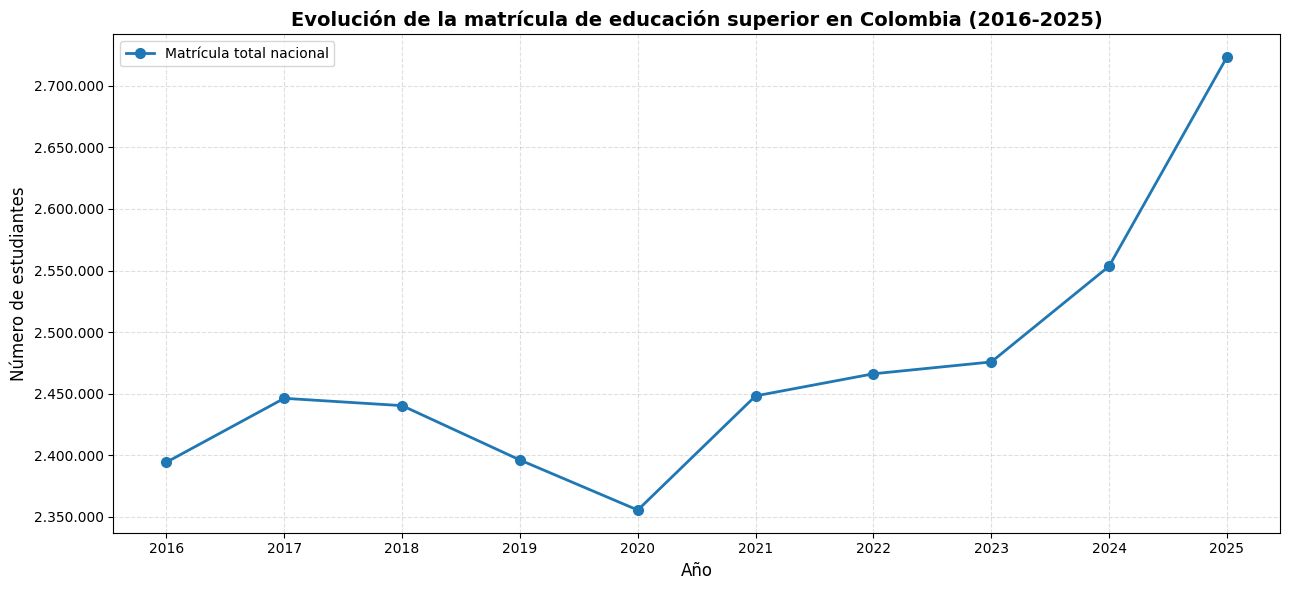

DATOS UTILIZADOS EN LA GRÁFICA


,año,matricula_total_nacional
0,2016,2394434
1,2017,2446314
2,2018,2440367
3,2019,2396250
4,2020,2355603
5,2021,2448271
6,2022,2466228
7,2023,2475833
8,2024,2553560
9,2025,2723364


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 11: GRÁFICA DE EVOLUCIÓN DE MATRÍCULA
# NACIONAL
# ============================================

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Ordenar los datos por año
datos_grafica = resumen_anual.copy()

datos_grafica = datos_grafica.sort_values("año")

# Convertir los datos a formatos numéricos compatibles
anios = datos_grafica["año"].astype(int).to_numpy()

matriculas = (
    datos_grafica["matricula_total_nacional"]
    .astype(float)
    .to_numpy()
)

# Crear la figura
plt.figure(figsize=(13, 6))

# Dibujar la evolución de la matrícula
plt.plot(
    anios,
    matriculas,
    marker="o",
    markersize=7,
    linewidth=2,
    label="Matrícula total nacional"
)

# Agregar título y etiquetas
plt.title(
    "Evolución de la matrícula de educación superior en Colombia (2016-2025)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Año", fontsize=12)
plt.ylabel("Número de estudiantes", fontsize=12)

# Formatear los valores del eje vertical
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicion: f"{valor:,.0f}".replace(",", "."))
)

# Configurar los años del eje horizontal
plt.xticks(anios)

# Agregar cuadrícula y leyenda
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.legend()

# Ajustar los márgenes
plt.tight_layout()

# Mostrar la gráfica
plt.show()

# Mostrar los datos utilizados
print("DATOS UTILIZADOS EN LA GRÁFICA")

display(
    datos_grafica[
        ["año", "matricula_total_nacional"]
    ]
)

La matrícula nacional más baja del periodo fue en 2020, con 2.355.603 estudiantes.



En 2025 se registró el valor más alto, con 2.723.364 estudiantes.



Entre 2016 y 2025 hubo un incremento de 328.930 matrículas, aproximadamente un 13,74 %.

TOP 10 TERRITORIOS CON MAYOR MATRÍCULA
AÑO 2025


,departamento,año,matricula_total
0,BOGOTÁ D.C.,2025,962349
1,ANTIOQUIA,2025,324877
2,VALLE DEL CAUCA,2025,193005
3,ATLÁNTICO,2025,149576
4,SANTANDER,2025,130898
5,CUNDINAMARCA,2025,98295
6,BOLÍVAR,2025,87562
7,BOYACÁ,2025,76916
8,NORTE DE SANTANDER,2025,72965
9,TOLIMA,2025,53186


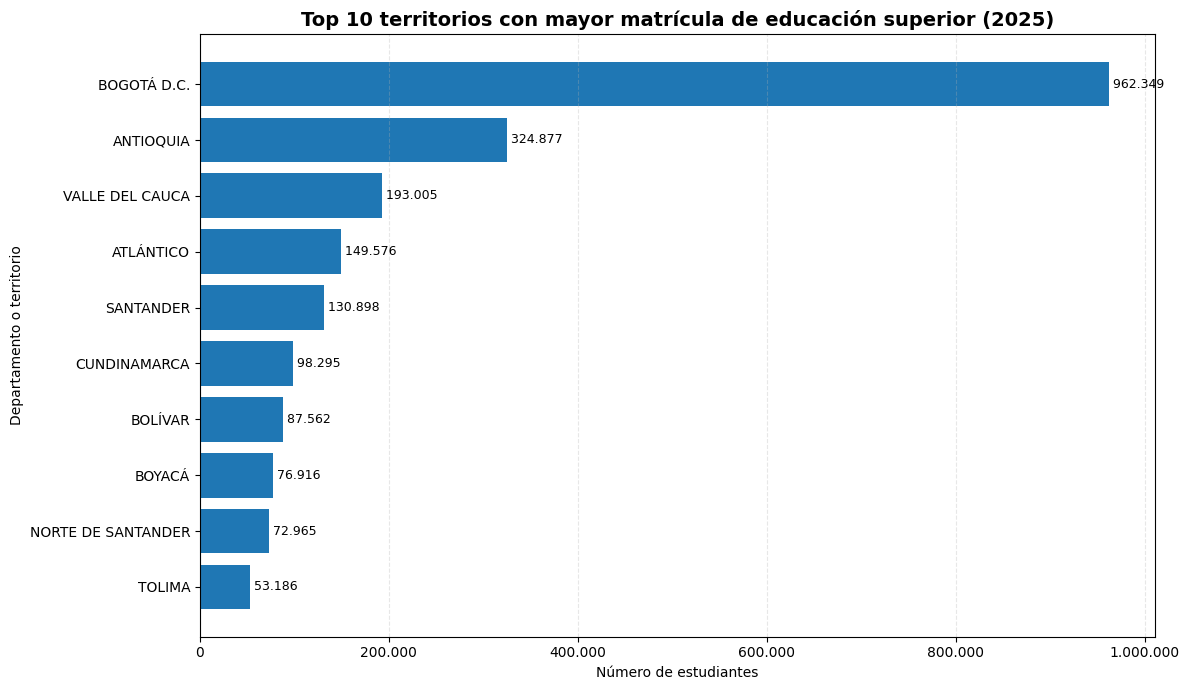


TERRITORIO CON MAYOR MATRÍCULA EN 2025
Departamento: BOGOTÁ D.C.
Matrícula: 962.349

Análisis del Top 10 finalizado.


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 12: TOP 10 TERRITORIOS EN 2025
# ============================================

from matplotlib.ticker import FuncFormatter

# Filtrar los registros del año 2025
datos_2025 = df[df["año"] == 2025].copy()

# Comprobar que existan registros
if datos_2025.empty:
    raise ValueError("No se encontraron registros para 2025.")

# Seleccionar los diez territorios con mayor matrícula
top_10_2025 = (
    datos_2025
    .nlargest(10, "matricula_total")
    .sort_values("matricula_total", ascending=True)
)

# Mostrar la tabla de resultados
print("==========================================")
print("TOP 10 TERRITORIOS CON MAYOR MATRÍCULA")
print("AÑO 2025")
print("==========================================")

display(
    top_10_2025[
        ["departamento", "año", "matricula_total"]
    ].sort_values(
        "matricula_total",
        ascending=False
    ).reset_index(drop=True)
)

# Crear la gráfica
plt.figure(figsize=(12, 7))

barras = plt.barh(
    top_10_2025["departamento"],
    top_10_2025["matricula_total"]
)

# Agregar los valores al final de cada barra
for barra in barras:

    valor = barra.get_width()

    plt.text(
        valor,
        barra.get_y() + barra.get_height() / 2,
        f" {valor:,.0f}".replace(",", "."),
        va="center",
        fontsize=9
    )

# Título y etiquetas
plt.title(
    "Top 10 territorios con mayor matrícula de educación superior (2025)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Número de estudiantes")
plt.ylabel("Departamento o territorio")

# Formato del eje horizontal
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, posicion: f"{valor:,.0f}".replace(",", ".")
    )
)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

# Mostrar gráfica
plt.show()

# Identificar el territorio con mayor matrícula
mayor_matricula = top_10_2025.loc[
    top_10_2025["matricula_total"].idxmax()
]

print("\nTERRITORIO CON MAYOR MATRÍCULA EN 2025")

print("Departamento:", mayor_matricula["departamento"])
print(
    "Matrícula:",
    f"{int(mayor_matricula['matricula_total']):,}".replace(",", ".")
)

print("\nAnálisis del Top 10 finalizado.")

Bogotá D. C. ocupa el primer lugar, con 962.349 matrículas, seguida de Antioquia con 324.877 y Valle del Cauca con 193.005.

In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 13: REVISIÓN DE MATRÍCULA NACIONAL
# POR SECTOR
# ============================================

# Cargar la hoja Nacional_Sector
nacional_sector = hojas["Nacional_Sector"].copy()

# Limpiar los encabezados
nacional_sector.columns = (
    nacional_sector.columns
    .astype(str)
    .str.strip()
)

print("==========================================")
print("MATRÍCULA NACIONAL POR SECTOR")
print("==========================================")

# Mostrar dimensiones
print("Número de registros:", len(nacional_sector))
print("Número de columnas:", len(nacional_sector.columns))

# Mostrar los nombres de las columnas
print("\nCOLUMNAS DISPONIBLES:")

for columna in nacional_sector.columns:
    print("-", columna)

# Mostrar los tipos de datos
print("\nTIPOS DE DATOS:")

display(
    nacional_sector.dtypes.to_frame(
        name="tipo_de_dato"
    )
)

# Mostrar todos los registros
print("\nINFORMACIÓN COMPLETA POR SECTOR:")

display(nacional_sector)

# Revisar valores faltantes
print("\nVALORES FALTANTES:")

display(
    nacional_sector.isna()
    .sum()
    .to_frame(name="valores_faltantes")
)

print("\nRevisión de matrícula nacional por sector finalizada.")

MATRÍCULA NACIONAL POR SECTOR
Número de registros: 10
Número de columnas: 6

COLUMNAS DISPONIBLES:
- año
- oficial
- privado
- matricula_total_sector
- estado
- fuente

TIPOS DE DATOS:


,tipo_de_dato
año,int64
oficial,int64
privado,int64
matricula_total_sector,int64
estado,object
fuente,object



INFORMACIÓN COMPLETA POR SECTOR:


,año,oficial,privado,matricula_total_sector,estado,fuente
0,2016,1194697,1199737,2394434,Completo: total nacional por sector,https://snies.mineducacion.gov.co/1778/article...
1,2017,1241790,1204524,2446314,Completo: total nacional por sector,https://snies.mineducacion.gov.co/1778/article...
2,2018,1242482,1197885,2440367,Completo: total nacional por sector,https://snies.mineducacion.gov.co/1778/article...
3,2019,1218130,1178120,2396250,Completo: total nacional por sector,https://snies.mineducacion.gov.co/1778/article...
4,2020,1203895,1151708,2355603,Completo: total nacional por sector,https://snies.mineducacion.gov.co/1778/article...
5,2021,1334174,1114097,2448271,Completo: total nacional por sector,https://snies.mineducacion.gov.co/1778/article...
6,2022,1341339,1124889,2466228,Completo: total nacional por sector,https://snies.mineducacion.gov.co/1778/article...
7,2023,1333971,1141862,2475833,Completo: total nacional por sector,https://snies.mineducacion.gov.co/1778/article...
8,2024,1401639,1151921,2553560,Completo: total nacional por sector,https://snies.mineducacion.gov.co/1778/article...
9,2025,1545484,1177880,2723364,Completo: total nacional por sector,https://snies.mineducacion.gov.co/1778/article...



VALORES FALTANTES:


,valores_faltantes
año,0
oficial,0
privado,0
matricula_total_sector,0
estado,0
fuente,0



Revisión de matrícula nacional por sector finalizada.


MATRÍCULA NACIONAL POR SECTOR
OFICIAL Y PRIVADO


,año,oficial,privado,matricula_total_sector,diferencia_total,porcentaje_oficial,porcentaje_privado
0,2016,1194697,1199737,2394434,0,49.89,50.11
1,2017,1241790,1204524,2446314,0,50.76,49.24
2,2018,1242482,1197885,2440367,0,50.91,49.09
3,2019,1218130,1178120,2396250,0,50.83,49.17
4,2020,1203895,1151708,2355603,0,51.11,48.89
5,2021,1334174,1114097,2448271,0,54.49,45.51
6,2022,1341339,1124889,2466228,0,54.39,45.61
7,2023,1333971,1141862,2475833,0,53.88,46.12
8,2024,1401639,1151921,2553560,0,54.89,45.11
9,2025,1545484,1177880,2723364,0,56.75,43.25



VALIDACIÓN DE LOS TOTALES
Años analizados: 10
Diferencias encontradas: 0
RESULTADO: LOS TOTALES COINCIDEN.


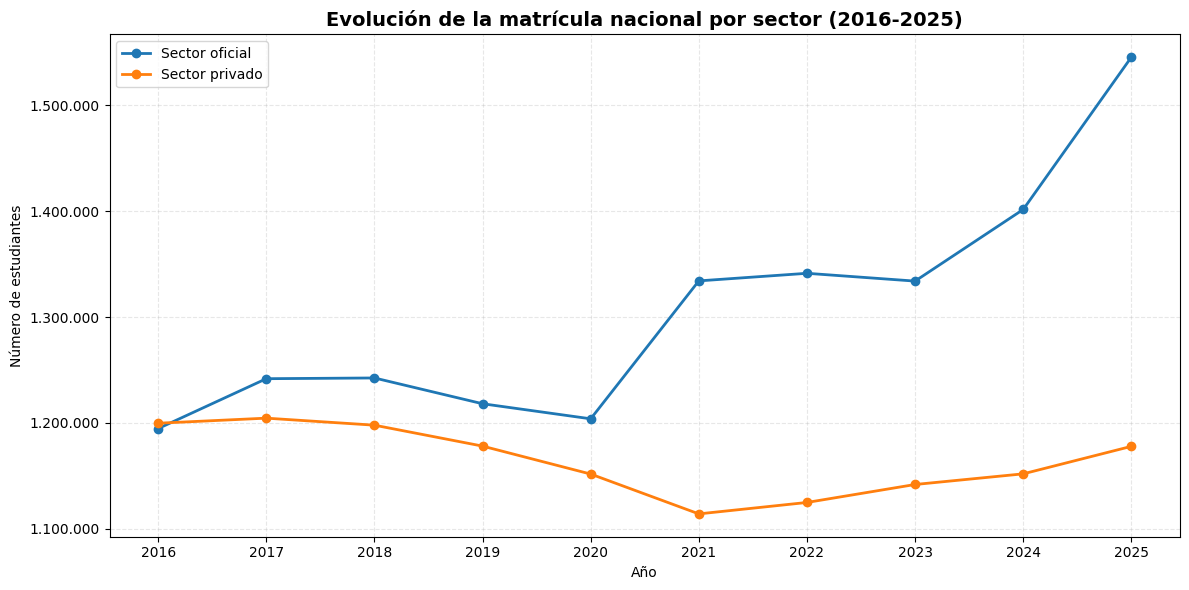


PARTICIPACIÓN PORCENTUAL POR SECTOR


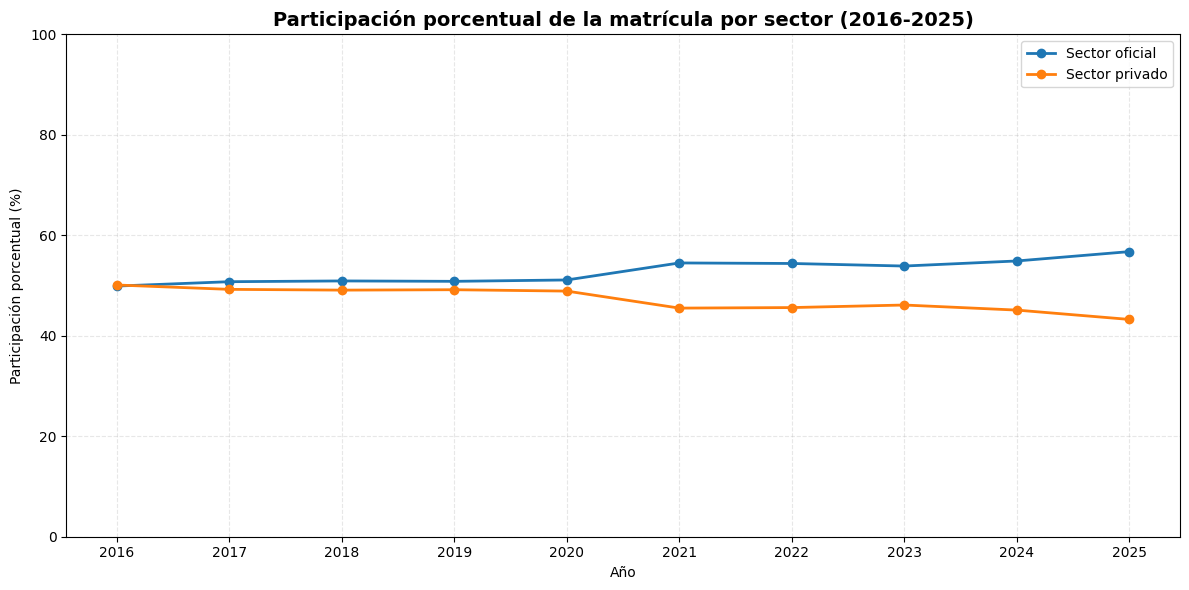


Análisis por sector finalizado correctamente.


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 14: ANÁLISIS POR SECTOR
# OFICIAL Y PRIVADO
# ============================================

# Crear una copia de los datos
sector = nacional_sector.copy()

# Ordenar los registros por año
sector = sector.sort_values("año").copy()

# Convertir las variables a valores numéricos
columnas_numericas = [
    "año",
    "oficial",
    "privado",
    "matricula_total_sector"
]

for columna in columnas_numericas:
    sector[columna] = pd.to_numeric(
        sector[columna],
        errors="coerce"
    )

# Calcular la suma de los dos sectores
sector["suma_oficial_privado"] = (
    sector["oficial"] + sector["privado"]
)

# Calcular la diferencia con el total nacional
sector["diferencia_total"] = (
    sector["matricula_total_sector"]
    - sector["suma_oficial_privado"]
)

# Calcular porcentajes de participación
sector["porcentaje_oficial"] = (
    sector["oficial"]
    / sector["matricula_total_sector"] * 100
)

sector["porcentaje_privado"] = (
    sector["privado"]
    / sector["matricula_total_sector"] * 100
)

# Mostrar la tabla de resultados
print("==========================================")
print("MATRÍCULA NACIONAL POR SECTOR")
print("OFICIAL Y PRIVADO")
print("==========================================")

display(
    sector[
        [
            "año",
            "oficial",
            "privado",
            "matricula_total_sector",
            "diferencia_total",
            "porcentaje_oficial",
            "porcentaje_privado"
        ]
    ].round(2)
)

# Validar que la suma de los sectores
# coincida con el total nacional
diferencias_sector = (
    sector["diferencia_total"] != 0
).sum()

print("\n==========================================")
print("VALIDACIÓN DE LOS TOTALES")
print("==========================================")

print("Años analizados:", len(sector))
print("Diferencias encontradas:", diferencias_sector)

if diferencias_sector == 0:
    print("RESULTADO: LOS TOTALES COINCIDEN.")
else:
    print("RESULTADO: SE DEBEN REVISAR LAS DIFERENCIAS.")

# ============================================
# GRÁFICA COMPARATIVA
# ============================================

plt.figure(figsize=(12, 6))

plt.plot(
    sector["año"],
    sector["oficial"],
    marker="o",
    linewidth=2,
    label="Sector oficial"
)

plt.plot(
    sector["año"],
    sector["privado"],
    marker="o",
    linewidth=2,
    label="Sector privado"
)

plt.title(
    "Evolución de la matrícula nacional por sector (2016-2025)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Año")
plt.ylabel("Número de estudiantes")

plt.xticks(
    sector["año"].astype(int)
)

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, posicion:
        f"{valor:,.0f}".replace(",", ".")
    )
)

plt.grid(
    True,
    linestyle="--",
    alpha=0.3
)

plt.legend()
plt.tight_layout()
plt.show()

# ============================================
# PARTICIPACIÓN PORCENTUAL
# ============================================

print("\nPARTICIPACIÓN PORCENTUAL POR SECTOR")

plt.figure(figsize=(12, 6))

plt.plot(
    sector["año"],
    sector["porcentaje_oficial"],
    marker="o",
    linewidth=2,
    label="Sector oficial"
)

plt.plot(
    sector["año"],
    sector["porcentaje_privado"],
    marker="o",
    linewidth=2,
    label="Sector privado"
)

plt.title(
    "Participación porcentual de la matrícula por sector (2016-2025)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Año")
plt.ylabel("Participación porcentual (%)")

plt.xticks(
    sector["año"].astype(int)
)

plt.ylim(0, 100)
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("\nAnálisis por sector finalizado correctamente.")

Hay tres hallazgos importantes:
1. En 2016, el sector privado tenía una participación ligeramente superior: 50,11 % frente al 49,89 % del oficial.
2. Desde 2017, el sector oficial pasó a representar más de la mitad de la matrícula nacional.
3. En 2025, el sector oficial alcanzó el 56,75 %, mientras que el privado representó el 43,25 %.

In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 15: REVISIÓN DE MATRÍCULA NACIONAL
# POR NIVEL DE FORMACIÓN
# ============================================

# Cargar la hoja Nacional_Niveles
nacional_niveles = hojas["Nacional_Niveles"].copy()

# Limpiar los nombres de las columnas
nacional_niveles.columns = (
    nacional_niveles.columns
    .astype(str)
    .str.strip()
)

print("==========================================")
print("MATRÍCULA NACIONAL POR NIVEL DE FORMACIÓN")
print("==========================================")

# Mostrar dimensiones
print("Número de registros:", len(nacional_niveles))
print("Número de columnas:", len(nacional_niveles.columns))

# Mostrar nombres de columnas
print("\nCOLUMNAS DISPONIBLES:")

for columna in nacional_niveles.columns:
    print("-", columna)

# Mostrar tipos de datos
print("\nTIPOS DE DATOS:")

display(
    nacional_niveles.dtypes.to_frame(
        name="tipo_de_dato"
    )
)

# Mostrar toda la información
print("\nINFORMACIÓN COMPLETA POR NIVEL:")

display(nacional_niveles)

# Revisar valores faltantes
print("\nVALORES FALTANTES:")

display(
    nacional_niveles.isna()
    .sum()
    .to_frame(name="valores_faltantes")
)

print("\nRevisión de niveles de formación finalizada.")

MATRÍCULA NACIONAL POR NIVEL DE FORMACIÓN
Número de registros: 10
Número de columnas: 7

COLUMNAS DISPONIBLES:
- año
- tecnica_profesional
- tecnologica
- universitaria
- total_pregado_si_completo
- estado
- fuente

TIPOS DE DATOS:


,tipo_de_dato
año,int64
tecnica_profesional,float64
tecnologica,float64
universitaria,int64
total_pregado_si_completo,float64
estado,object
fuente,object



INFORMACIÓN COMPLETA POR NIVEL:


,año,tecnica_profesional,tecnologica,universitaria,total_pregado_si_completo,estado,fuente
0,2016,NaN,NaN,1513288,NaN,Parcial: solo se encontró valor universitario;...,https://snies.mineducacion.gov.co/1778/article...
1,2017,73263.0,658579.0,1548485,2280327.0,Completo: pregrado nacional por nivel,https://snies.mineducacion.gov.co/1778/article...
2,2018,78474.0,631072.0,1557594,2267140.0,Completo: pregrado nacional por nivel,https://snies.mineducacion.gov.co/1778/article...
3,2019,81805.0,574730.0,1552078,2208613.0,Completo: pregrado nacional por nivel,https://snies.mineducacion.gov.co/1778/article...
4,2020,68903.0,581479.0,1529788,2180170.0,Completo: pregrado nacional por nivel,https://snies.mineducacion.gov.co/1778/article...
5,2021,74098.0,617679.0,1568193,2259970.0,Completo: pregrado nacional por nivel,https://snies.mineducacion.gov.co/1778/article...
6,2022,82994.0,613092.0,1588551,2284637.0,Completo: pregrado nacional por nivel,https://snies.mineducacion.gov.co/1778/article...
7,2023,90837.0,583917.0,1606093,2280847.0,Completo: pregrado nacional por nivel,https://snies.mineducacion.gov.co/1778/article...
8,2024,95389.0,613932.0,1637436,2346757.0,Completo: pregrado nacional por nivel,https://snies.mineducacion.gov.co/1778/article...
9,2025,106420.0,677726.0,1712508,2496654.0,Completo: pregrado nacional por nivel,https://snies.mineducacion.gov.co/1778/article...



VALORES FALTANTES:


,valores_faltantes
año,0
tecnica_profesional,1
tecnologica,1
universitaria,0
total_pregado_si_completo,1
estado,0
fuente,0



Revisión de niveles de formación finalizada.


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 16: VALIDACIÓN DE MATRÍCULA
# NACIONAL POR NIVEL DE FORMACIÓN
# ============================================

# Crear una copia de la información
niveles = nacional_niveles.copy()

# Organizar los datos por año
niveles = niveles.sort_values("año").copy()

# Columnas numéricas
columnas_niveles = [
    "tecnica_profesional",
    "tecnologica",
    "universitaria",
    "total_pregado_si_completo"
]

# Convertir los valores a formato numérico
for columna in columnas_niveles:

    niveles[columna] = pd.to_numeric(
        niveles[columna],
        errors="coerce"
    )

# Verificar que los tres niveles estén disponibles
niveles["datos_completos"] = niveles[
    [
        "tecnica_profesional",
        "tecnologica",
        "universitaria"
    ]
].notna().all(axis=1)

# Calcular la suma de los tres niveles
niveles["suma_tres_niveles"] = niveles[
    [
        "tecnica_profesional",
        "tecnologica",
        "universitaria"
    ]
].sum(axis=1, min_count=3)

# Calcular la diferencia respecto al total de pregrado
niveles["diferencia"] = (
    niveles["total_pregado_si_completo"]
    - niveles["suma_tres_niveles"]
)

# Mostrar los resultados
print("==========================================")
print("VALIDACIÓN POR NIVEL DE FORMACIÓN")
print("==========================================")

display(
    niveles[
        [
            "año",
            "tecnica_profesional",
            "tecnologica",
            "universitaria",
            "suma_tres_niveles",
            "total_pregado_si_completo",
            "diferencia",
            "datos_completos"
        ]
    ]
)

# Separar años completos e incompletos
niveles_completos = niveles[
    niveles["datos_completos"]
].copy()

niveles_incompletos = niveles[
    ~niveles["datos_completos"]
].copy()

# Contar diferencias entre los años completos
diferencias_niveles = (
    niveles_completos["diferencia"].abs() > 0
).sum()

print("\n==========================================")
print("RESULTADOS DE LA VALIDACIÓN")
print("==========================================")

print("Años registrados:", len(niveles))
print("Años con información completa:", len(niveles_completos))
print("Años con información parcial:", len(niveles_incompletos))
print("Diferencias en años completos:", diferencias_niveles)

if diferencias_niveles == 0:
    print("\nRESULTADO: LOS TOTALES COINCIDEN.")
else:
    print("\nRESULTADO: SE DEBEN REVISAR LAS DIFERENCIAS.")

# Mostrar años incompletos
if not niveles_incompletos.empty:

    print("\nAÑOS CON INFORMACIÓN PARCIAL:")

    display(
        niveles_incompletos[
            [
                "año",
                "tecnica_profesional",
                "tecnologica",
                "universitaria",
                "total_pregado_si_completo"
            ]
        ]
    )

print("\nValidación por nivel finalizada.")

VALIDACIÓN POR NIVEL DE FORMACIÓN


,año,tecnica_profesional,tecnologica,universitaria,suma_tres_niveles,total_pregado_si_completo,diferencia,datos_completos
0,2016,NaN,NaN,1513288,NaN,NaN,NaN,False
1,2017,73263.0,658579.0,1548485,2280327.0,2280327.0,0.0,True
2,2018,78474.0,631072.0,1557594,2267140.0,2267140.0,0.0,True
3,2019,81805.0,574730.0,1552078,2208613.0,2208613.0,0.0,True
4,2020,68903.0,581479.0,1529788,2180170.0,2180170.0,0.0,True
5,2021,74098.0,617679.0,1568193,2259970.0,2259970.0,0.0,True
6,2022,82994.0,613092.0,1588551,2284637.0,2284637.0,0.0,True
7,2023,90837.0,583917.0,1606093,2280847.0,2280847.0,0.0,True
8,2024,95389.0,613932.0,1637436,2346757.0,2346757.0,0.0,True
9,2025,106420.0,677726.0,1712508,2496654.0,2496654.0,0.0,True



RESULTADOS DE LA VALIDACIÓN
Años registrados: 10
Años con información completa: 9
Años con información parcial: 1
Diferencias en años completos: 0

RESULTADO: LOS TOTALES COINCIDEN.

AÑOS CON INFORMACIÓN PARCIAL:


,año,tecnica_profesional,tecnologica,universitaria,total_pregado_si_completo
0,2016,NaN,NaN,1513288,NaN



Validación por nivel finalizada.


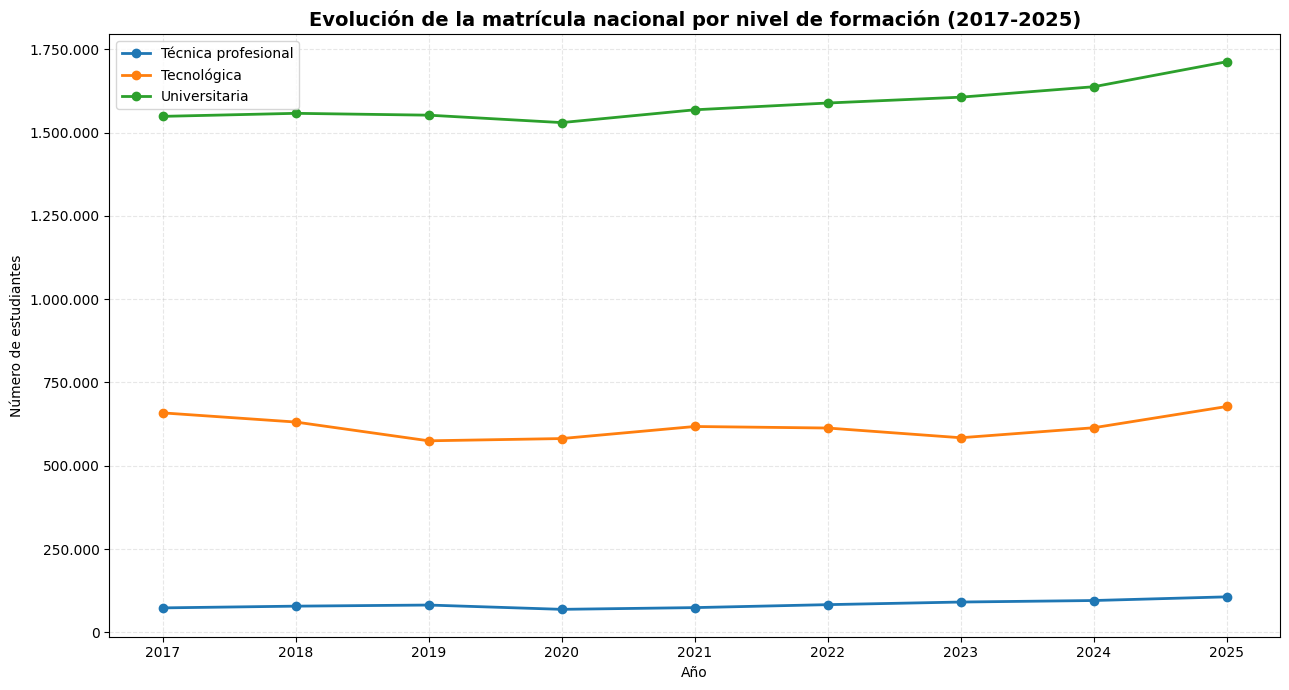

DATOS UTILIZADOS EN LA GRÁFICA


,año,tecnica_profesional,tecnologica,universitaria
1,2017,73263.0,658579.0,1548485
2,2018,78474.0,631072.0,1557594
3,2019,81805.0,574730.0,1552078
4,2020,68903.0,581479.0,1529788
5,2021,74098.0,617679.0,1568193
6,2022,82994.0,613092.0,1588551
7,2023,90837.0,583917.0,1606093
8,2024,95389.0,613932.0,1637436
9,2025,106420.0,677726.0,1712508


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 17: GRÁFICA POR NIVEL DE FORMACIÓN
# ============================================

# Utilizar solamente años completos
datos_grafica_niveles = niveles[
    niveles["datos_completos"]
].copy()

# Ordenar por año
datos_grafica_niveles = (
    datos_grafica_niveles.sort_values("año")
)

# Crear figura
plt.figure(figsize=(13, 7))

# Graficar nivel técnico profesional
plt.plot(
    datos_grafica_niveles["año"],
    datos_grafica_niveles["tecnica_profesional"],
    marker="o",
    linewidth=2,
    label="Técnica profesional"
)

# Graficar nivel tecnológico
plt.plot(
    datos_grafica_niveles["año"],
    datos_grafica_niveles["tecnologica"],
    marker="o",
    linewidth=2,
    label="Tecnológica"
)

# Graficar nivel universitario
plt.plot(
    datos_grafica_niveles["año"],
    datos_grafica_niveles["universitaria"],
    marker="o",
    linewidth=2,
    label="Universitaria"
)

# Título y etiquetas
plt.title(
    "Evolución de la matrícula nacional por nivel de formación (2017-2025)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Año")
plt.ylabel("Número de estudiantes")

# Configurar eje horizontal
plt.xticks(
    datos_grafica_niveles["año"].astype(int)
)

# Formato del eje vertical
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, posicion:
        f"{valor:,.0f}".replace(",", ".")
    )
)

# Cuadrícula y leyenda
plt.grid(
    True,
    linestyle="--",
    alpha=0.3
)

plt.legend()
plt.tight_layout()

# Mostrar gráfica
plt.show()

# Mostrar la información utilizada
print("DATOS UTILIZADOS EN LA GRÁFICA")

display(
    datos_grafica_niveles[
        [
            "año",
            "tecnica_profesional",
            "tecnologica",
            "universitaria"
        ]
    ]
)

Técnica profesional: pasó de 73.263 matrículas en 2017 a 106.420 en 2025.



Tecnológica: pasó de 658.579 a 677.726.



Universitaria: pasó de 1.548.485 a 1.712.508.

La gráfica permite observar que el nivel universitario registra la mayor cantidad de matrículas durante todo el periodo analizado.

In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 18: ANÁLISIS ESTADÍSTICO POR
# NIVEL DE FORMACIÓN
# ============================================

# Variables que vamos a analizar
variables_niveles = {
    "tecnica_profesional": "Técnica profesional",
    "tecnologica": "Tecnológica",
    "universitaria": "Universitaria"
}

# Crear lista para almacenar resultados
resultados_niveles = []

# Analizar cada nivel
for columna, nombre in variables_niveles.items():

    serie = (
        datos_grafica_niveles
        .set_index("año")[columna]
        .dropna()
        .sort_index()
    )

    # Valores inicial y final
    anio_inicial = int(serie.index[0])
    anio_final = int(serie.index[-1])

    valor_inicial = int(serie.iloc[0])
    valor_final = int(serie.iloc[-1])

    # Variación absoluta
    variacion_absoluta = valor_final - valor_inicial

    # Variación porcentual
    variacion_porcentual = (
        (valor_final - valor_inicial)
        / valor_inicial * 100
    )

    # Identificar máximo y mínimo
    anio_maximo = int(serie.idxmax())
    valor_maximo = int(serie.max())

    anio_minimo = int(serie.idxmin())
    valor_minimo = int(serie.min())

    # Guardar resultados
    resultados_niveles.append({
        "nivel_formacion": nombre,
        "matricula_inicial": valor_inicial,
        "año_inicial": anio_inicial,
        "matricula_final": valor_final,
        "año_final": anio_final,
        "variacion_absoluta": variacion_absoluta,
        "variacion_porcentual": round(
            variacion_porcentual, 2
        ),
        "año_maximo": anio_maximo,
        "matricula_maxima": valor_maximo,
        "año_minimo": anio_minimo,
        "matricula_minima": valor_minimo
    })

# Crear tabla de resultados
resumen_niveles = pd.DataFrame(resultados_niveles)

# Mostrar resultados
print("==========================================")
print("RESUMEN ESTADÍSTICO POR NIVEL")
print("PERIODO 2017-2025")
print("==========================================")

display(resumen_niveles)

# Calcular variación porcentual anual
variacion_anual_niveles = (
    datos_grafica_niveles[
        ["año"] + list(variables_niveles.keys())
    ].copy()
)

for columna in variables_niveles:

    variacion_anual_niveles[
        columna + "_variacion_porcentual"
    ] = (
        variacion_anual_niveles[columna]
        .pct_change() * 100
    ).round(2)

# Mostrar variaciones
print("\n==========================================")
print("VARIACIÓN PORCENTUAL ANUAL")
print("==========================================")

display(variacion_anual_niveles)

print("\nAnálisis estadístico finalizado correctamente.")

RESUMEN ESTADÍSTICO POR NIVEL
PERIODO 2017-2025


,nivel_formacion,matricula_inicial,año_inicial,matricula_final,año_final,variacion_absoluta,variacion_porcentual,año_maximo,matricula_maxima,año_minimo,matricula_minima
0,Técnica profesional,73263,2017,106420,2025,33157,45.26,2025,106420,2020,68903
1,Tecnológica,658579,2017,677726,2025,19147,2.91,2025,677726,2019,574730
2,Universitaria,1548485,2017,1712508,2025,164023,10.59,2025,1712508,2020,1529788



VARIACIÓN PORCENTUAL ANUAL


,año,tecnica_profesional,tecnologica,universitaria,tecnica_profesional_variacion_porcentual,tecnologica_variacion_porcentual,universitaria_variacion_porcentual
1,2017,73263.0,658579.0,1548485,NaN,NaN,NaN
2,2018,78474.0,631072.0,1557594,7.11,-4.18,0.59
3,2019,81805.0,574730.0,1552078,4.24,-8.93,-0.35
4,2020,68903.0,581479.0,1529788,-15.77,1.17,-1.44
5,2021,74098.0,617679.0,1568193,7.54,6.23,2.51
6,2022,82994.0,613092.0,1588551,12.01,-0.74,1.30
7,2023,90837.0,583917.0,1606093,9.45,-4.76,1.10
8,2024,95389.0,613932.0,1637436,5.01,5.14,1.95
9,2025,106420.0,677726.0,1712508,11.56,10.39,4.58



Análisis estadístico finalizado correctamente.


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 19: DESCARGA DE BASES OFICIALES
# ESTUDIANTES MATRICULADOS
# ============================================

import os
import requests
import zipfile
import pandas as pd

from pathlib import Path

# Carpeta de almacenamiento
carpeta_bases = Path("/content/BASES_OFICIALES_SNIES")
carpeta_bases.mkdir(parents=True, exist_ok=True)

# Identificadores de los archivos oficiales
identificadores = {
    2016: "391577",
    2017: "391576",
    2018: "391575",
    2019: "401908",
    2020: "406671",
    2021: "411252",
    2022: "416244",
    2023: "421539",
    2024: "425151",
    2025: "430149"
}

# Descargar cada archivo
bases_descargadas = {}
errores_descarga = []

sesion = requests.Session()
sesion.headers.update({
    "User-Agent": "Mozilla/5.0"
})

print("INICIANDO DESCARGA DE BASES OFICIALES")
print("=" * 55)

for anio, identificador in identificadores.items():

    url = (
        "https://snies.mineducacion.gov.co/1778/"
        f"articles-{identificador}_recurso.xlsx"
    )

    ruta = carpeta_bases / f"Matriculados_SNIES_{anio}.xlsx"

    try:

        respuesta = sesion.get(
            url,
            timeout=180
        )

        respuesta.raise_for_status()

        # Comprobar que el archivo sea realmente Excel
        if not respuesta.content.startswith(b"PK"):
            raise ValueError(
                "El contenido recibido no parece ser un archivo XLSX."
            )

        with open(ruta, "wb") as archivo:
            archivo.write(respuesta.content)

        if not zipfile.is_zipfile(ruta):
            ruta.unlink(missing_ok=True)
            raise ValueError("El archivo descargado no es un Excel válido.")

        bases_descargadas[anio] = str(ruta)

        tamanio_mb = os.path.getsize(ruta) / (1024 ** 2)

        print(
            f"{anio}: DESCARGADO CORRECTAMENTE "
            f"({tamanio_mb:.2f} MB)"
        )

    except Exception as error:

        errores_descarga.append({
            "año": anio,
            "error": str(error)
        })

        print(f"{anio}: ERROR - {error}")

print("\n" + "=" * 55)
print("RESUMEN DE DESCARGAS")
print("=" * 55)

print("Bases descargadas:", len(bases_descargadas))
print("Bases con errores:", len(errores_descarga))

print("\nArchivos disponibles:")

for anio, ruta in bases_descargadas.items():
    print(anio, "->", ruta)

if errores_descarga:

    print("\nAÑOS QUE NECESITAN REVISIÓN:")

    display(pd.DataFrame(errores_descarga))

print("\nProceso de descarga finalizado.")

INICIANDO DESCARGA DE BASES OFICIALES
2016: DESCARGADO CORRECTAMENTE (8.42 MB)
2017: DESCARGADO CORRECTAMENTE (9.00 MB)
2018: DESCARGADO CORRECTAMENTE (8.54 MB)
2019: DESCARGADO CORRECTAMENTE (11.03 MB)
2020: DESCARGADO CORRECTAMENTE (10.97 MB)
2021: DESCARGADO CORRECTAMENTE (11.79 MB)
2022: DESCARGADO CORRECTAMENTE (11.56 MB)
2023: DESCARGADO CORRECTAMENTE (12.12 MB)
2024: DESCARGADO CORRECTAMENTE (12.94 MB)
2025: DESCARGADO CORRECTAMENTE (17.99 MB)

RESUMEN DE DESCARGAS
Bases descargadas: 10
Bases con errores: 0

Archivos disponibles:
2016 -> /content/BASES_OFICIALES_SNIES/Matriculados_SNIES_2016.xlsx
2017 -> /content/BASES_OFICIALES_SNIES/Matriculados_SNIES_2017.xlsx
2018 -> /content/BASES_OFICIALES_SNIES/Matriculados_SNIES_2018.xlsx
2019 -> /content/BASES_OFICIALES_SNIES/Matriculados_SNIES_2019.xlsx
2020 -> /content/BASES_OFICIALES_SNIES/Matriculados_SNIES_2020.xlsx
2021 -> /content/BASES_OFICIALES_SNIES/Matriculados_SNIES_2021.xlsx
2022 -> /content/BASES_OFICIALES_SNIES/Matriculad

In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 21: IDENTIFICAR ENCABEZADOS REALES
# DE LAS BASES OFICIALES
# ============================================

import pandas as pd
import numpy as np

def inspeccionar_base(anio, ruta):

    libro = pd.ExcelFile(ruta, engine="openpyxl")

    # Excluir hojas que sean únicamente índices
    hojas_datos = [
        hoja for hoja in libro.sheet_names
        if "indice" not in hoja.lower()
        and "índice" not in hoja.lower()
    ]

    if not hojas_datos:
        hojas_datos = libro.sheet_names

    # Seleccionar la primera hoja de datos
    hoja = hojas_datos[0]

    # Leer sin encabezados
    datos_crudos = pd.read_excel(
        ruta,
        sheet_name=hoja,
        header=None,
        nrows=35,
        dtype=object
    )

    # Limitar la inspección a las primeras 15 columnas
    datos_crudos = datos_crudos.iloc[:, :15]

    filas = []

    for numero_fila, valores in datos_crudos.iterrows():

        contenido = []

        for numero_columna, valor in enumerate(valores):

            if pd.notna(valor):

                texto = str(valor).replace("\n", " ").strip()

                if texto:
                    contenido.append(
                        f"Columna {numero_columna + 1}: {texto[:90]}"
                    )

        if contenido:

            filas.append({
                "fila_excel": numero_fila + 1,
                "contenido": " | ".join(contenido)
            })

    print("\n" + "=" * 80)
    print("AÑO:", anio)
    print("HOJA:", hoja)
    print("=" * 80)

    display(pd.DataFrame(filas))


# Inspeccionar todas las bases descargadas
for anio, ruta in sorted(bases_descargadas.items()):

    inspeccionar_base(anio, ruta)

print("\nINSPECCIÓN DE ENCABEZADOS FINALIZADA.")


AÑO: 2016
HOJA: Matriculados_2016


,fila_excel,contenido
0,1,Columna 1: MINISTERIO DE EDUCACIÓN NACIONAL
1,2,Columna 1: MATRICULADOS EN EDUCACIÓN SUPERIOR ...
2,3,Columna 1: Fecha de corte de la información: M...
3,4,Columna 1: Fuente: Ministerio de Educación Nac...
4,5,Columna 1: La información suministrada corresp...
...,...,...
29,31,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...
30,32,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...
31,33,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...
32,34,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...



AÑO: 2017
HOJA: Hoja1


,fila_excel,contenido
0,1,Columna 1: MINISTERIO DE EDUCACIÓN NACIONAL
1,2,Columna 1: MATRICULADOS EN EDUCACIÓN SUPERIOR ...
2,3,Columna 1: Fecha de corte de la información: A...
3,4,Columna 1: Fuente: Ministerio de Educación Nac...
4,5,Columna 1: La información suministrada corresp...
...,...,...
29,31,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...
30,32,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...
31,33,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...
32,34,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...



AÑO: 2018
HOJA: Sheet1


,fila_excel,contenido
0,2,Columna 1: MATRICULADOS EN EDUCACIÓN SUPERIOR ...
1,3,Columna 1: Fecha de corte de la información: J...
2,4,Columna 1: Fuente: Ministerio de Educación Nac...
3,5,Columna 1: La información suministrada corresp...
4,6,"Columna 1: Nota: Para el año 2018, de las 300 ..."
...,...,...
28,31,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...
29,32,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...
30,33,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...
31,34,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...


... (11 outputs left out)

,fila_excel,contenido
0,1,Columna 3: MINISTERIO DE EDUCACIÓN NACIONAL
1,2,Columna 3: SUBDIRECCIÓN DE DESARROLLO SECTORIAL
2,3,Columna 3: ESTUDIANTES MATRICULADOS EN INSTITU...
3,4,Columna 3: AÑO 2024
4,5,Columna 1: VOLVER AL INDICE
...,...,...
30,31,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...
31,32,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...
32,33,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...
33,34,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...



AÑO: 2025
HOJA: 1.


,fila_excel,contenido
0,1,Columna 3: MINISTERIO DE EDUCACIÓN NACIONAL
1,2,Columna 3: SUBDIRECCIÓN DE DESARROLLO SECTORIAL
2,3,Columna 3: ESTUDIANTES MATRICULADOS EN INSTITU...
3,4,Columna 3: AÑO 2025
4,5,Columna 1: VOLVER AL INDICE
...,...,...
30,31,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...
31,32,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...
32,33,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...
33,34,Columna 1: 1101 | Columna 2: 1101 | Columna 3:...



INSPECCIÓN DE ENCABEZADOS FINALIZADA.


In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 22: INSPECCIÓN PROFUNDA DE EXCEL
# ============================================

from openpyxl import load_workbook
from openpyxl.utils import get_column_letter

# Palabras que pueden identificar los encabezados
palabras_clave = [
    "DEPARTAMENTO",
    "SECTOR",
    "NIVEL",
    "MATRICUL",
    "INSTITUC",
    "PROGRAMA",
    "MODALIDAD",
    "FORMACION",
    "FORMACIÓN",
    "CARACTER",
    "CARÁCTER",
    "ESTUDIANTE",
    "CODIGO",
    "CÓDIGO",
    "OFICIAL",
    "PRIVADO"
]

for anio, ruta in sorted(bases_descargadas.items()):

    print("\n" + "=" * 90)
    print("AÑO:", anio)
    print("=" * 90)

    # Abrir el libro sin modificarlo
    libro = load_workbook(
        ruta,
        read_only=True,
        data_only=True
    )

    # Seleccionar la hoja de información
    hojas_datos = [
        nombre for nombre in libro.sheetnames
        if "indice" not in nombre.lower()
        and "índice" not in nombre.lower()
    ]

    if not hojas_datos:
        hojas_datos = libro.sheetnames

    nombre_hoja = hojas_datos[0]
    ws = libro[nombre_hoja]

    print("Hoja:", nombre_hoja)
    print("Filas totales:", ws.max_row)
    print("Columnas totales:", ws.max_column)

    # Mostrar las primeras 45 filas
    print("\nCONTENIDO DE LAS PRIMERAS 45 FILAS")

    limite_filas = min(ws.max_row, 45)
    limite_columnas = min(ws.max_column, 35)

    for numero_fila in range(1, limite_filas + 1):

        valores = []

        for numero_columna in range(1, limite_columnas + 1):

            valor = ws.cell(
                row=numero_fila,
                column=numero_columna
            ).value

            if valor is not None:

                texto = str(valor).replace("\n", " ").strip()

                if texto:

                    letra = get_column_letter(numero_columna)

                    valores.append(
                        f"{letra}={texto[:75]}"
                    )

        if valores:

            print(
                f"Fila {numero_fila}:",
                " | ".join(valores)
            )

    # Buscar posibles filas de encabezados
    print("\nPOSIBLES FILAS DE ENCABEZADOS")

    encontradas = 0

    for numero_fila in range(1, min(ws.max_row, 150) + 1):

        valores_fila = []

        for numero_columna in range(1, ws.max_column + 1):

            valor = ws.cell(
                row=numero_fila,
                column=numero_columna
            ).value

            if isinstance(valor, str):

                texto = valor.upper().strip()

                if texto:
                    valores_fila.append(texto)

        texto_completo = " ".join(valores_fila)

        coincidencias = [
            palabra for palabra in palabras_clave
            if palabra in texto_completo
        ]

        # Mostrar filas que contengan varias palabras clave
        if len(coincidencias) >= 2:

            print(
                f"Fila {numero_fila}: "
                f"{coincidencias}"
            )

            encontradas += 1

            if encontradas >= 15:
                break

    if encontradas == 0:
        print("No se identificaron encabezados automáticamente.")

    libro.close()

print("\nINSPECCIÓN PROFUNDA FINALIZADA.")


AÑO: 2016
Hoja: Matriculados_2016
Filas totales: 60370
Columnas totales: 47

CONTENIDO DE LAS PRIMERAS 45 FILAS
Fila 1: A=MINISTERIO DE EDUCACIÓN NACIONAL
Fila 2: A=MATRICULADOS EN EDUCACIÓN SUPERIOR - COLOMBIA 2016
Fila 3: A=Fecha de corte de la información: Mayo 15 de 2017
Fila 4: A=Fuente: Ministerio de Educación Nacional - Sistema Nacional de Información 
Fila 5: A=La información suministrada corresponde a lo reportado por las Institucione
Fila 7: A=Código de  la Institución | B=IES PADRE | C=Institución de Educación Superior (IES) | D=Principal  o Seccional | E=ID Sector IES | F=Sector IES | G=ID Caracter | H=Caracter IES | I=Código del  departamento (IES) | J=Departamento de  domicilio de la IES | K=Código del  Municipio (IES) | L=Municipio de domicilio de la IES | M=Código  SNIES del programa | N=Programa Académico | O=ID Nivel Académico | P=Nivel Académico | Q=ID Nivel de Formación | R=Nivel de Formación | S=ID Metodología | T=Metodología | U=ID Área | V=Área de Conocimiento |

In [ ]:
# ============================================
# PROYECTO: DATASET SNIES 2016-2025
# CÓDIGO 23: IDENTIFICAR COLUMNAS IMPORTANTES
# EN TODAS LAS BASES ANUALES
# ============================================

from openpyxl import load_workbook
from openpyxl.utils import get_column_letter
import unicodedata

def normalizar_texto(valor):

    if valor is None:
        return ""

    texto = str(valor).upper().strip()

    texto = unicodedata.normalize(
        "NFKD",
        texto
    )

    texto = "".join(
        caracter for caracter in texto
        if not unicodedata.combining(caracter)
    )

    return " ".join(texto.split())


# Palabras que necesitamos identificar
palabras = [
    "DEPARTAMENTO",
    "OFERTA DEL PROGRAMA",
    "SECTOR IES",
    "NIVEL ACADEMICO",
    "NIVEL DE FORMACION",
    "MATRICULADOS",
    "SEMESTRE",
    "INSTITUCION",
    "ANO"
]

# Diccionario para almacenar las estructuras encontradas
estructuras_snies = {}

for anio, ruta in sorted(bases_descargadas.items()):

    print("\n" + "=" * 75)
    print("AÑO:", anio)
    print("=" * 75)

    libro = load_workbook(
        ruta,
        read_only=True,
        data_only=True
    )

    # Excluir hojas que sean índices
    hojas_datos = [
        nombre for nombre in libro.sheetnames
        if "indice" not in normalizar_texto(nombre)
    ]

    if not hojas_datos:
        hojas_datos = libro.sheetnames

    encontrado = False

    for nombre_hoja in hojas_datos:

        ws = libro[nombre_hoja]

        mejor_fila = None
        mejor_puntuacion = 0

        # Buscar los encabezados en las primeras 60 filas
        for numero_fila in range(
            1,
            min(ws.max_row, 60) + 1
        ):

            valores = [
                normalizar_texto(
                    ws.cell(numero_fila, columna).value
                )
                for columna in range(1, ws.max_column + 1)
            ]

            texto_fila = " ".join(valores)

            puntuacion = sum(
                1 for palabra in palabras
                if palabra in texto_fila
            )

            if puntuacion > mejor_puntuacion:

                mejor_puntuacion = puntuacion
                mejor_fila = numero_fila

        # Exigir una fila con suficientes encabezados
        if mejor_fila is not None and mejor_puntuacion >= 4:

            encabezados = {}

            for columna in range(1, ws.max_column + 1):

                valor = ws.cell(
                    mejor_fila,
                    columna
                ).value

                if valor is not None:

                    letra = get_column_letter(columna)

                    encabezados[letra] = str(valor).strip()

            estructuras_snies[anio] = {
                "hoja": nombre_hoja,
                "fila_encabezado": mejor_fila,
                "encabezados": encabezados
            }

            print("Hoja encontrada:", nombre_hoja)
            print("Fila de encabezados:", mejor_fila)
            print("Coincidencias:", mejor_puntuacion)

            print("\nCOLUMNAS RELEVANTES:")

            for letra, nombre in encabezados.items():

                nombre_normalizado = normalizar_texto(nombre)

                if any(
                    palabra in nombre_normalizado
                    for palabra in palabras
                ):

                    print(f"{letra}: {nombre}")

            encontrado = True
            break

    if not encontrado:

        print(
            "No se encontró automáticamente una fila "
            "de encabezados con la estructura esperada."
        )

    libro.close()


print("\n" + "=" * 75)
print("RESUMEN DE ESTRUCTURAS IDENTIFICADAS")
print("=" * 75)

print("Años identificados:", len(estructuras_snies))

for anio, datos in estructuras_snies.items():

    print(
        f"{anio}: hoja={datos['hoja']}, "
        f"fila={datos['fila_encabezado']}"
    )


AÑO: 2016
Hoja encontrada: Matriculados_2016
Fila de encabezados: 7
Coincidencias: 9

COLUMNAS RELEVANTES:
A: Código de 
la Institución
C: Institución de Educación Superior (IES)
E: ID Sector IES
F: Sector IES
I: Código del 
departamento
(IES)
J: Departamento de 
domicilio de la IES
O: ID Nivel Académico
P: Nivel Académico
Q: ID Nivel de Formación
R: Nivel de Formación
Y: Código del 
Departamento
(Programa)
Z: Departamento de oferta del programa
AB: Municipio de oferta del programa
AE: Año
AF: Semestre
AG: Matriculados 2016

AÑO: 2017
Hoja encontrada: Hoja1
Fila de encabezados: 7
Coincidencias: 9

COLUMNAS RELEVANTES:
A: Código de 
la Institución
C: Institución de Educación Superior (IES)
E: ID Sector IES
F: Sector IES
I: Código del 
departamento
(IES)
J: Departamento de 
domicilio de la IES
O: ID Nivel Académico
P: Nivel Académico
Q: ID Nivel de Formación
R: Nivel de Formación
Y: Código del 
Departamento
(Programa)
Z: Departamento de oferta del programa
AB: Municipio de oferta del pr